In [1]:
import pandas as pd
import numpy as np

print("My E-Commerce Purchase Prediction Project has started!")
print("Python environment is working correctly.")


My E-Commerce Purchase Prediction Project has started!
Python environment is working correctly.


In [2]:
# Load the e-commerce dataset

import pandas as pd

df = pd.read_csv("../data/raw/online_shoppers_intention.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 12330
Number of columns: 18


In [5]:
print(df.columns.tolist())

['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


In [6]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [7]:
# Display all column names

for column in df.columns:
    print(column)

Administrative
Administrative_Duration
Informational
Informational_Duration
ProductRelated
ProductRelated_Duration
BounceRates
ExitRates
PageValues
SpecialDay
Month
OperatingSystems
Browser
Region
TrafficType
VisitorType
Weekend
Revenue


In [8]:
# Check data types and non-null values

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [9]:
# Count missing values in each column

print(df.isnull().sum())


Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


In [10]:
# Count duplicate rows

print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 125


In [11]:
# Count purchase and non-purchase sessions

print(df["Revenue"].value_counts())

Revenue
False    10422
True      1908
Name: count, dtype: int64


In [12]:
# Calculate percentage distribution

print(
    df["Revenue"].value_counts(normalize=True) * 100
)


Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


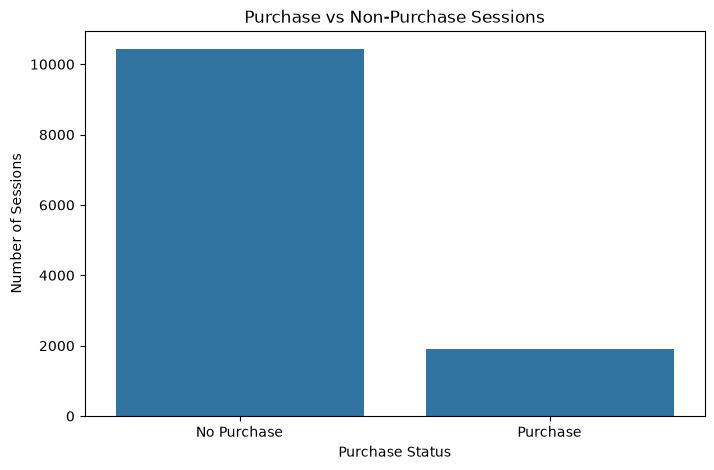

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Revenue"
)

plt.title("Purchase vs Non-Purchase Sessions")
plt.xlabel("Purchase Status")
plt.ylabel("Number of Sessions")

plt.xticks(
    [0, 1],
    ["No Purchase", "Purchase"]
)

plt.show()

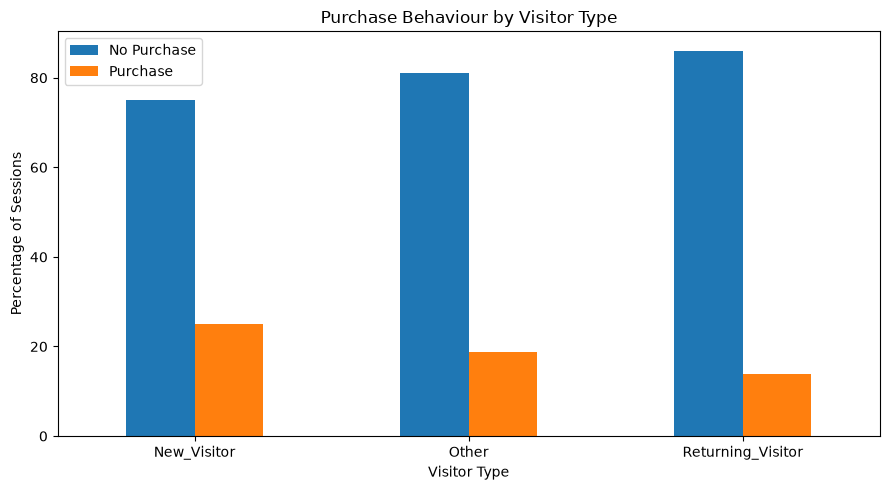

In [14]:
visitor_purchase = pd.crosstab(
    df["VisitorType"],
    df["Revenue"],
    normalize="index"
) * 100

visitor_purchase.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Purchase Behaviour by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Percentage of Sessions")
plt.legend(["No Purchase", "Purchase"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

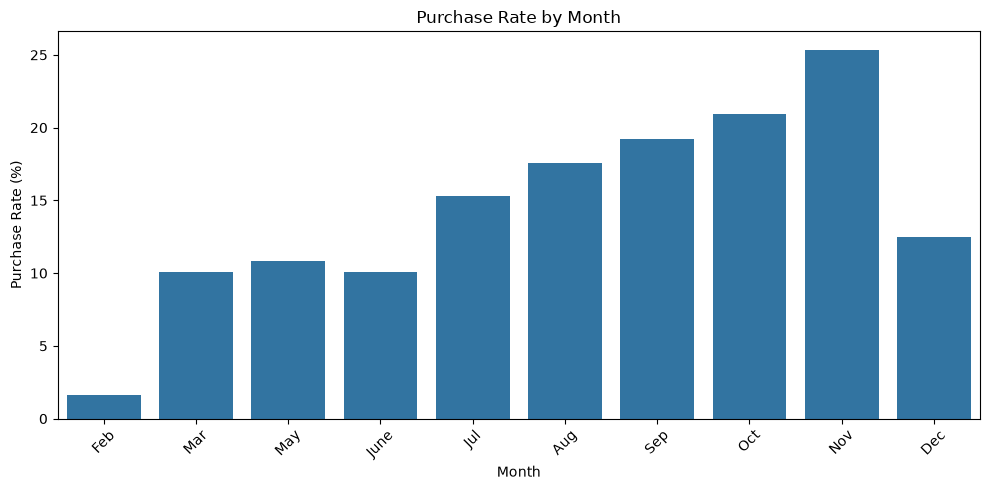

In [15]:
monthly_purchase = df.groupby("Month")["Revenue"].mean() * 100

month_order = [
    "Feb", "Mar", "May", "June",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_purchase = monthly_purchase.reindex(month_order)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_purchase.index,
    y=monthly_purchase.values
)

plt.title("Purchase Rate by Month")
plt.xlabel("Month")
plt.ylabel("Purchase Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [16]:
df.describe()


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


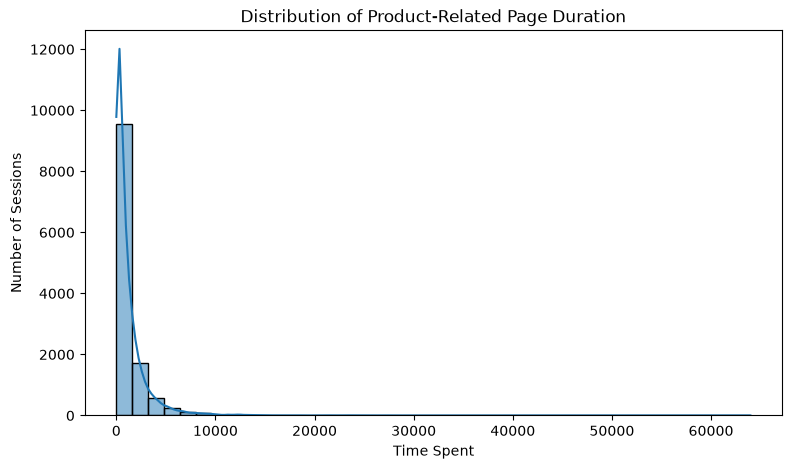

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="ProductRelated_Duration",
    bins=40,
    kde=True
)

plt.title("Distribution of Product-Related Page Duration")
plt.xlabel("Time Spent")
plt.ylabel("Number of Sessions")

plt.show()

In [18]:
visitor_analysis = pd.crosstab(
    df["VisitorType"],
    df["Revenue"],
    normalize="index"
) * 100

print(visitor_analysis.round(2))


Revenue            False  True 
VisitorType                    
New_Visitor        75.09  24.91
Other              81.18  18.82
Returning_Visitor  86.07  13.93


In [19]:
duration_analysis = df.groupby("Revenue")[
    "ProductRelated_Duration"
].agg(["mean", "median", "min", "max"])

print(duration_analysis)

                mean      median  min          max
Revenue                                           
False    1069.987809   510.19000  0.0  63973.52223
True     1876.209615  1109.90625  0.0  27009.85943


# Exploratory Data Analysis Findings

1. The dataset contains 12,330 shopping sessions.

2. There are 10,422 non-purchase sessions and
   1,908 purchase sessions.

3. The purchase rate is approximately 15.47%.

4. The dataset contains 125 duplicate rows,
   which require further investigation.

5. The target variable is imbalanced.

6. Purchase behaviour will be investigated across
   visitor types and months.

7. Numerical features will be examined to understand
   their distributions and possible outliers.

In [20]:
november_data = df[df["Month"] == "Nov"]

print("Total November sessions:", len(november_data))

print("\nNovember purchase distribution:")
print(november_data["Revenue"].value_counts())

print("\nNovember purchase rate:")
print(
    november_data["Revenue"].mean() * 100
)


Total November sessions: 2998

November purchase distribution:
Revenue
False    2238
True      760
Name: count, dtype: int64

November purchase rate:
25.350233488992664


In [21]:
# Display duplicate records

duplicate_rows = df[df.duplicated(keep=False)]

print("Total rows involved in duplicates:", len(duplicate_rows))

duplicate_rows.head(10)

# Check how many duplicate rows exist beyond their first occurrence

print("Duplicate rows:", df.duplicated().sum())

Total rows involved in duplicates: 201
Duplicate rows: 125


Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType'],
      dtype='str')


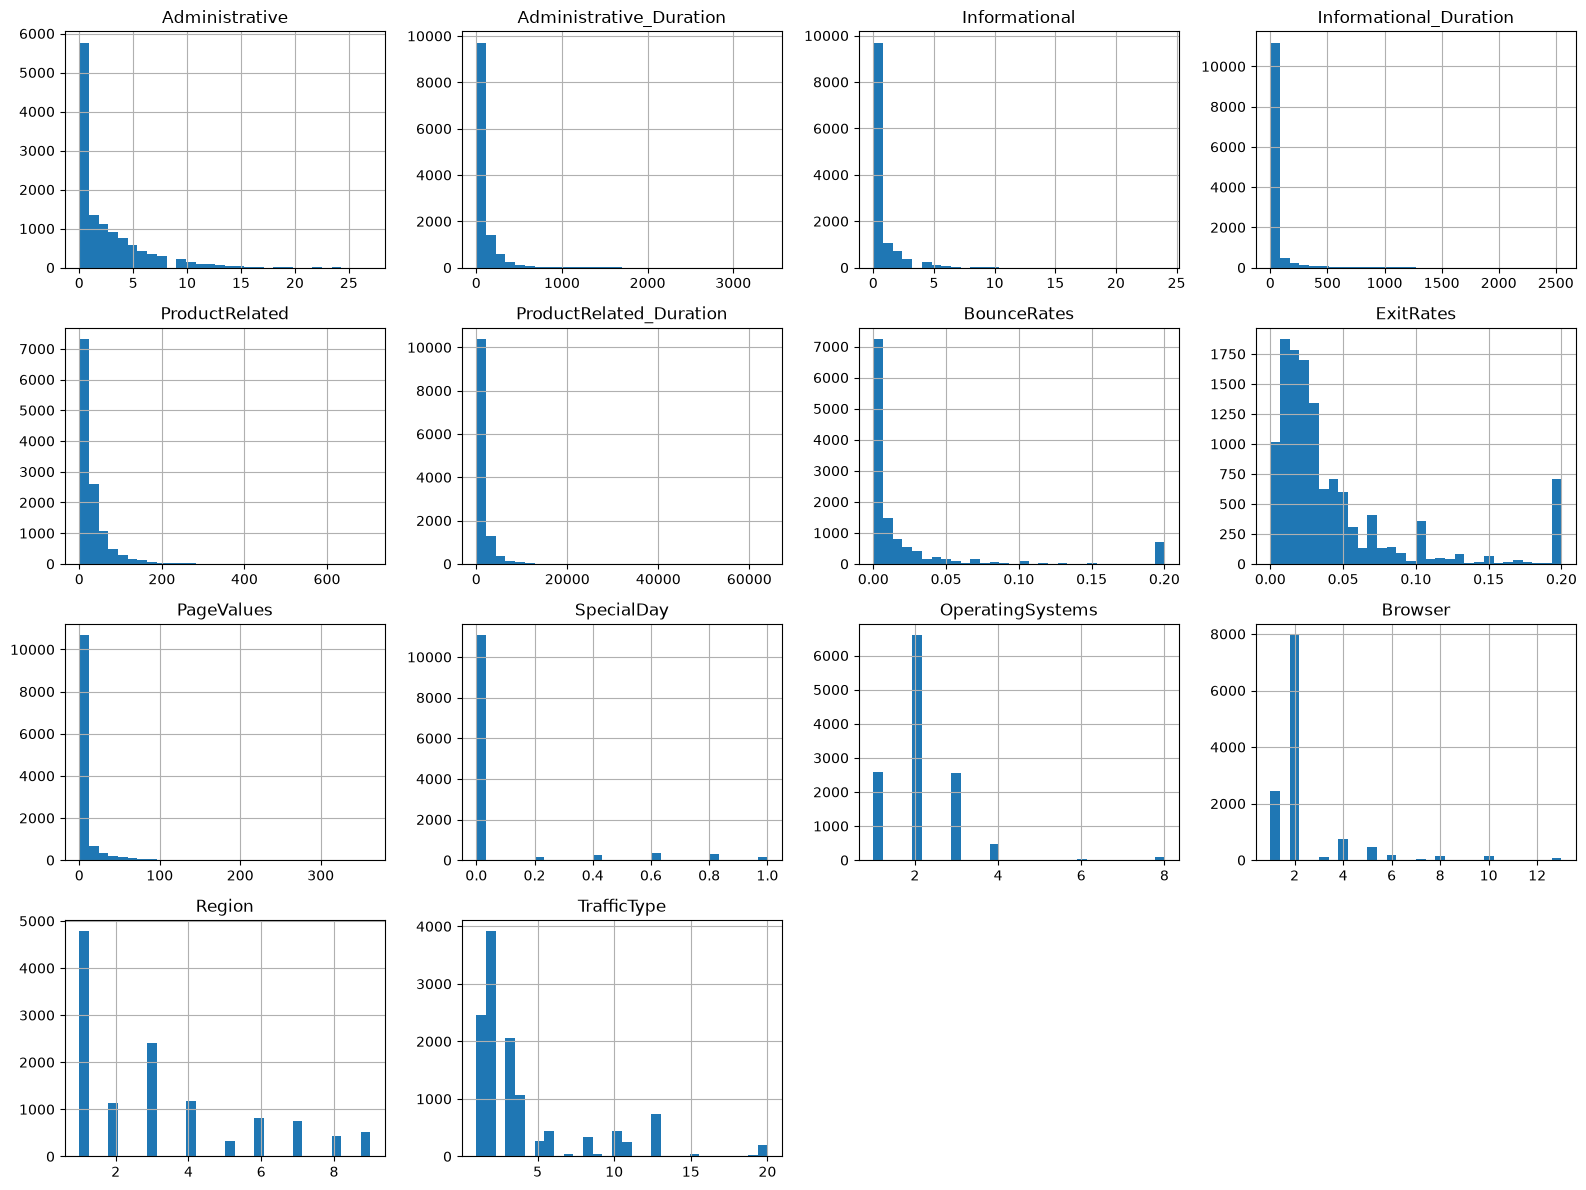

In [22]:
# Select numerical columns

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

print(numerical_columns)

# Visualise numerical feature distributions

df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()
plt.show()

# EDA Summary

## Dataset Overview
- Total records: 12,330
- Total features including target: 18
- Missing values: 0
- Duplicate rows: 125

## Target Distribution
- Purchase sessions: 1,908
- Non-purchase sessions: 10,422
- Purchase rate: 15.47%

## Initial Observations
- The target variable is imbalanced.
- New visitors outnumber returning visitors.
- November showed a high purchase rate in the initial analysis.
- Product-related browsing duration requires further analysis.
- Duplicate records require investigation.
- Numerical features require distribution and outlier analysis.

## Next Steps
- Investigate duplicates.
- Analyse feature relationships.
- Prepare preprocessing pipelines.
- Train classification models.

E-COMMERCE CUSTOMER PURCHASE PREDICTION - EDA

DATASET LOADED SUCCESSFULLY
Shape: (12330, 18)

FIRST FIVE RECORDS
   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       

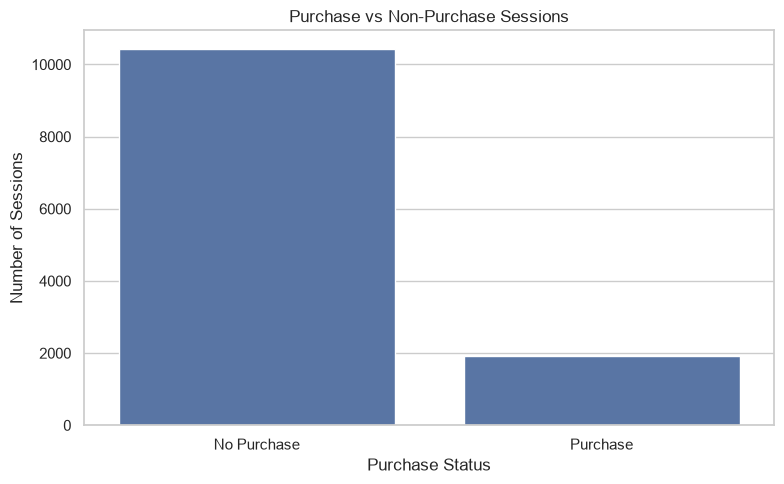


PURCHASE RATE BY VISITOR TYPE
Revenue            False  True 
VisitorType                    
New_Visitor        75.09  24.91
Other              81.18  18.82
Returning_Visitor  86.07  13.93


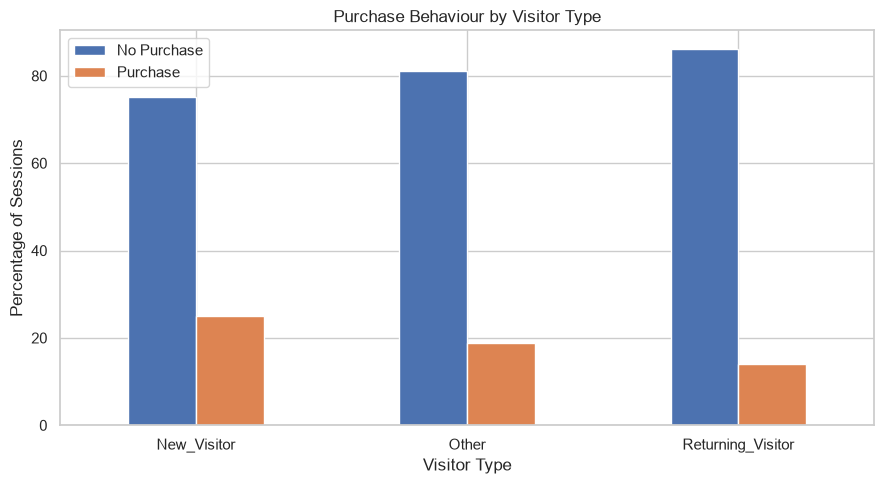


PRODUCT-RELATED DURATION ANALYSIS
                mean      median  min          max
Revenue                                           
False    1069.987809   510.19000  0.0  63973.52223
True     1876.209615  1109.90625  0.0  27009.85943


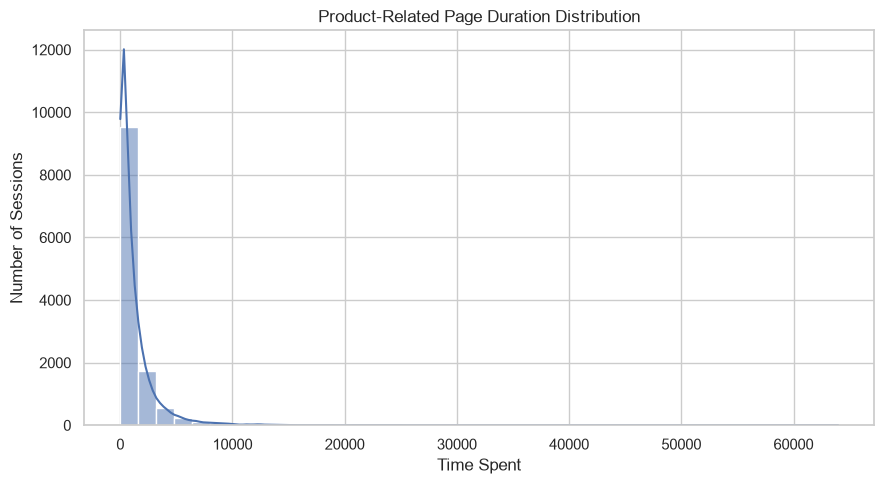


MONTHLY PURCHASE ANALYSIS
       count  sum  mean  purchase_rate
Month                                 
Feb      184    3  0.02           1.63
Mar     1907  192  0.10          10.07
May     3364  365  0.11          10.85
June     288   29  0.10          10.07
Jul      432   66  0.15          15.28
Aug      433   76  0.18          17.55
Sep      448   86  0.19          19.20
Oct      549  115  0.21          20.95
Nov     2998  760  0.25          25.35
Dec     1727  216  0.13          12.51


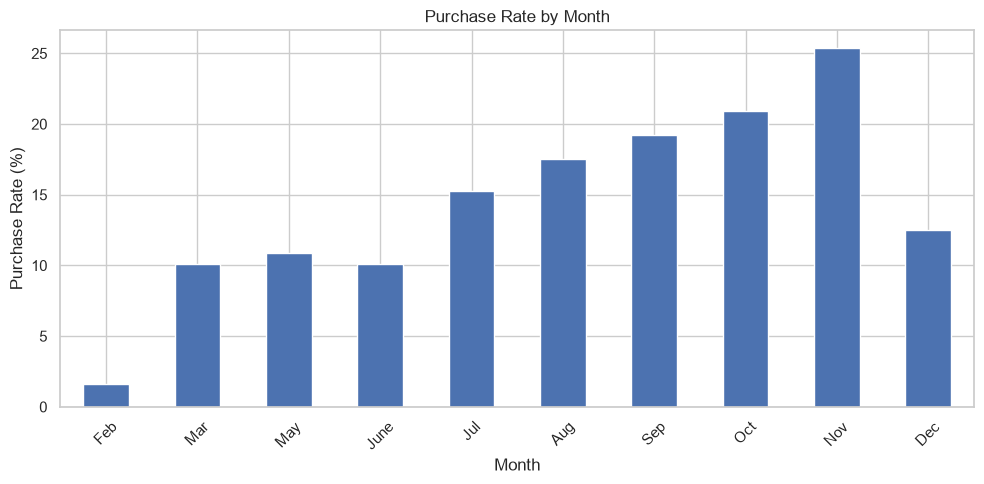


NUMERICAL COLUMNS
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


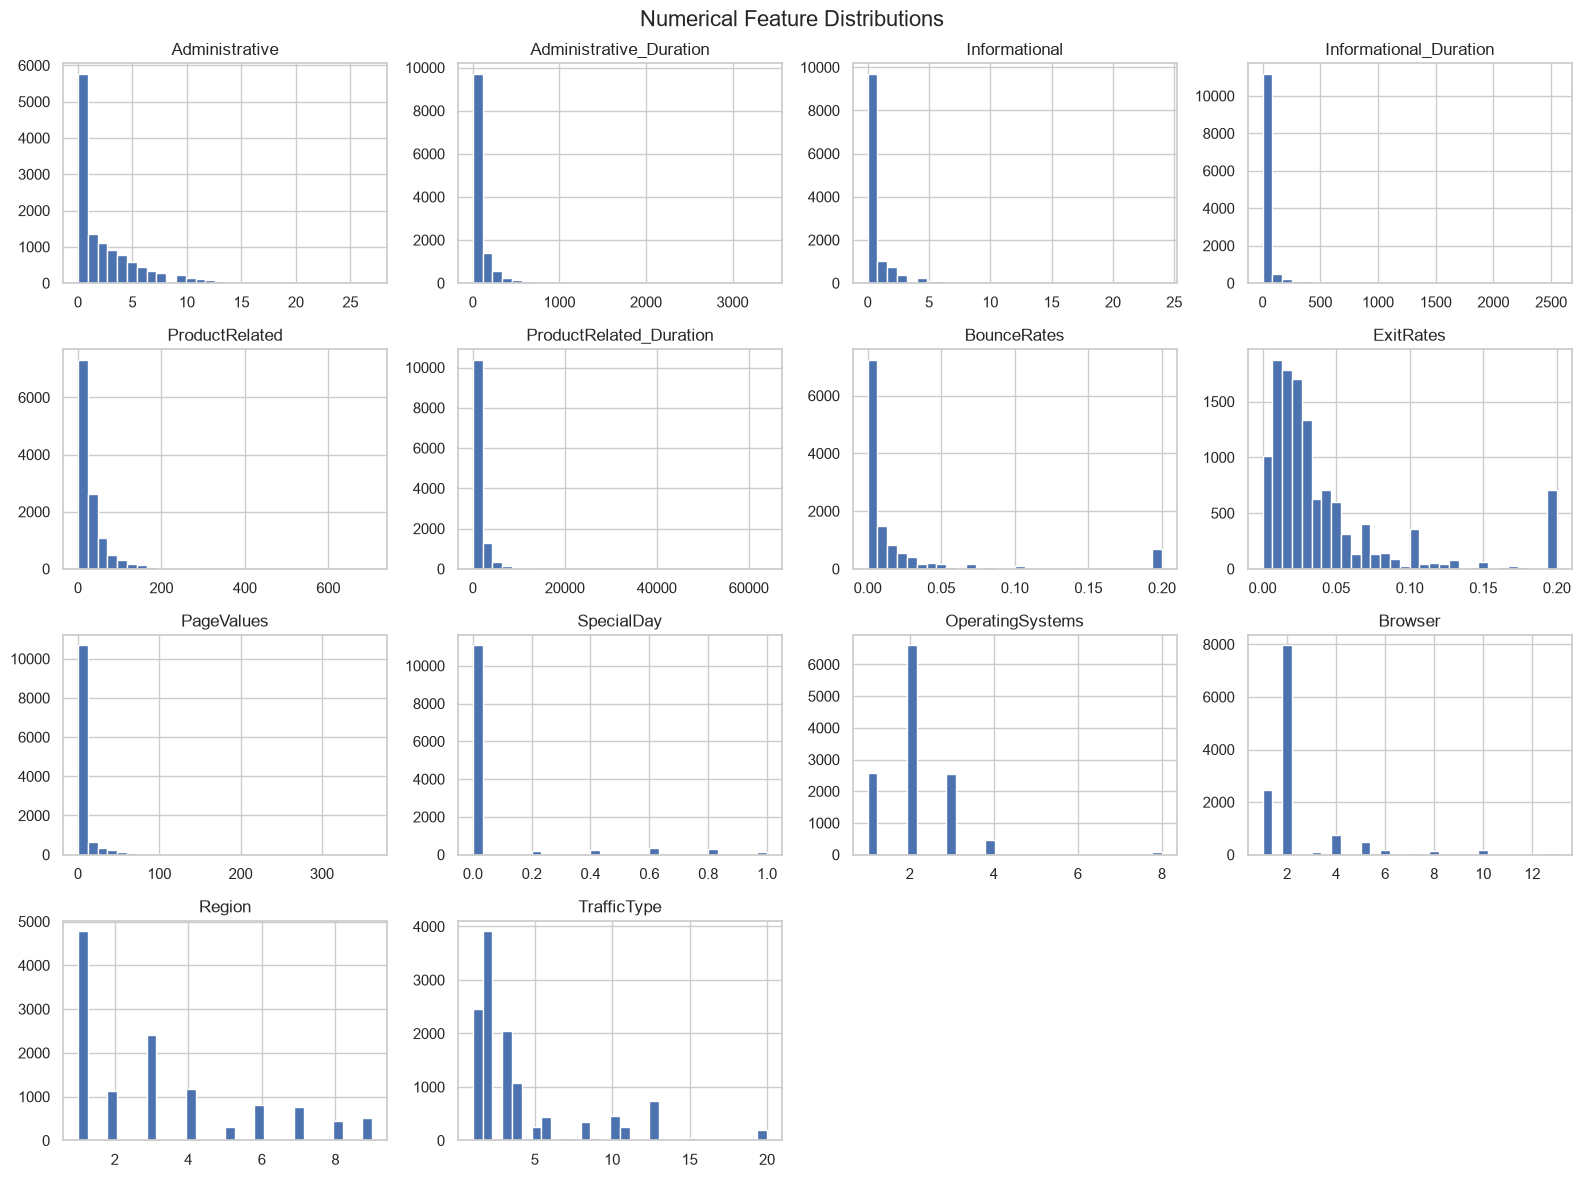

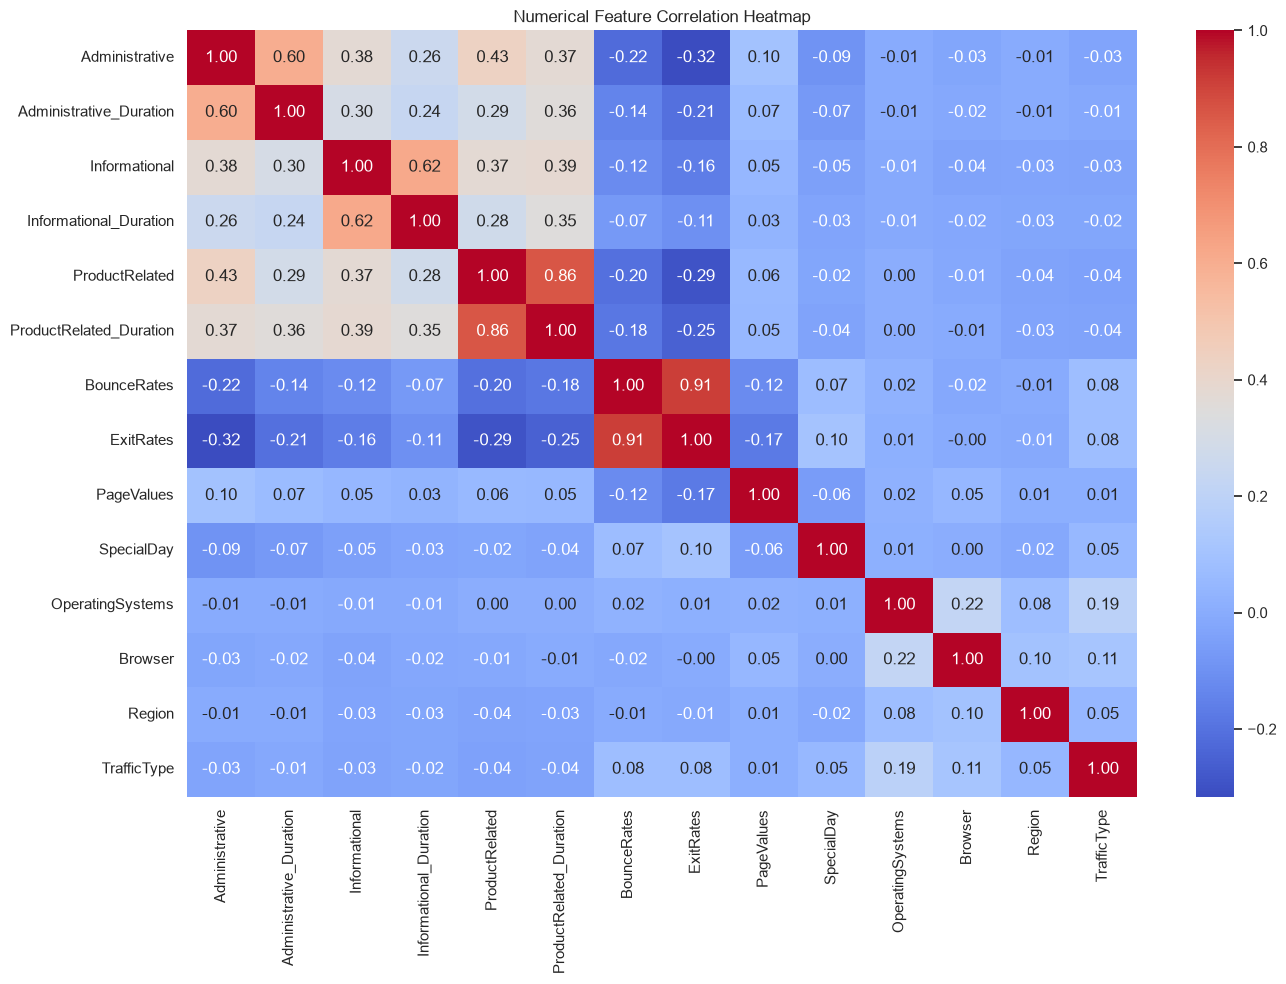


PURCHASE RATE BY WEEKEND
         count  mean  purchase_rate
Weekend                            
False     9462  0.15          14.89
True      2868  0.17          17.40

PURCHASE RATE BY SPECIAL DAY
            count  mean  purchase_rate
SpecialDay                            
0.0         11079  0.17          16.53
0.2           178  0.08           7.87
0.4           243  0.05           5.35
0.6           351  0.08           8.26
0.8           325  0.03           3.38
1.0           154  0.06           6.49

OUTLIER INVESTIGATION
Administrative : 404 potential outliers
Administrative_Duration : 1172 potential outliers
Informational : 2631 potential outliers
Informational_Duration : 2405 potential outliers
ProductRelated : 987 potential outliers
ProductRelated_Duration : 961 potential outliers
BounceRates : 1551 potential outliers
ExitRates : 1099 potential outliers
PageValues : 2730 potential outliers
SpecialDay : 1251 potential outliers
OperatingSystems : 111 potential outliers
Browser

In [23]:

# ============================================================
# E-COMMERCE CUSTOMER PURCHASE PREDICTION
# COMPLETE EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("=" * 60)
print("E-COMMERCE CUSTOMER PURCHASE PREDICTION - EDA")
print("=" * 60)


# 2. LOAD DATASET

df = pd.read_csv("../data/raw/online_shoppers_intention.csv")

print("\nDATASET LOADED SUCCESSFULLY")
print("Shape:", df.shape)


# 3. DISPLAY FIRST FIVE RECORDS

print("\nFIRST FIVE RECORDS")
print(df.head())


# 4. DATASET INFORMATION

print("\nDATASET INFORMATION")
df.info()


# 5. COLUMN NAMES

print("\nCOLUMN NAMES")
for column in df.columns:
    print(column)


# 6. MISSING VALUES

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nTOTAL MISSING VALUES:", df.isnull().sum().sum())


# 7. DUPLICATE RECORDS

print("\nDUPLICATE RECORDS")
print("Duplicate rows:", df.duplicated().sum())

duplicate_rows = df[df.duplicated(keep=False)]

print("\nSample duplicate records:")
print(duplicate_rows.head(10))


# 8. STATISTICAL SUMMARY

print("\nSTATISTICAL SUMMARY")
print(df.describe())


# 9. TARGET VARIABLE DISTRIBUTION

print("\nPURCHASE DISTRIBUTION")
print(df["Revenue"].value_counts())

print("\nPURCHASE PERCENTAGES")
print(df["Revenue"].value_counts(normalize=True) * 100)

purchase_rate = df["Revenue"].mean() * 100

print("\nOVERALL PURCHASE RATE:", round(purchase_rate, 2), "%")


# 10. GRAPH: PURCHASE VS NON-PURCHASE

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Revenue")

plt.title("Purchase vs Non-Purchase Sessions")
plt.xlabel("Purchase Status")
plt.ylabel("Number of Sessions")
plt.xticks([0, 1], ["No Purchase", "Purchase"])

plt.tight_layout()
plt.show()


# 11. GRAPH: PURCHASE BEHAVIOUR BY VISITOR TYPE

visitor_purchase = pd.crosstab(
    df["VisitorType"],
    df["Revenue"],
    normalize="index"
) * 100

print("\nPURCHASE RATE BY VISITOR TYPE")
print(visitor_purchase.round(2))

visitor_purchase.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Purchase Behaviour by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Percentage of Sessions")
plt.legend(["No Purchase", "Purchase"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 12. PRODUCT-RELATED PAGE DURATION ANALYSIS

duration_analysis = df.groupby("Revenue")[
    "ProductRelated_Duration"
].agg(["mean", "median", "min", "max"])

print("\nPRODUCT-RELATED DURATION ANALYSIS")
print(duration_analysis)


# 13. GRAPH: PRODUCT-RELATED DURATION DISTRIBUTION

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="ProductRelated_Duration",
    bins=40,
    kde=True
)

plt.title("Product-Related Page Duration Distribution")
plt.xlabel("Time Spent")
plt.ylabel("Number of Sessions")

plt.tight_layout()
plt.show()


# 14. MONTHLY PURCHASE ANALYSIS

monthly_analysis = df.groupby("Month")["Revenue"].agg(
    ["count", "sum", "mean"]
)

monthly_analysis["purchase_rate"] = (
    monthly_analysis["mean"] * 100
)

month_order = [
    "Feb", "Mar", "May", "June", "Jul",
    "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_analysis = monthly_analysis.reindex(month_order)

print("\nMONTHLY PURCHASE ANALYSIS")
print(monthly_analysis.round(2))

monthly_analysis["purchase_rate"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Purchase Rate by Month")
plt.xlabel("Month")
plt.ylabel("Purchase Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 15. NUMERICAL FEATURE HISTOGRAMS

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

print("\nNUMERICAL COLUMNS")
print(list(numerical_columns))

df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle("Numerical Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()


# 16. CORRELATION HEATMAP

numeric_df = df.select_dtypes(include=["number"])

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


# 17. PURCHASE RATE BY WEEKEND

weekend_analysis = df.groupby("Weekend")["Revenue"].agg(
    ["count", "mean"]
)

weekend_analysis["purchase_rate"] = (
    weekend_analysis["mean"] * 100
)

print("\nPURCHASE RATE BY WEEKEND")
print(weekend_analysis.round(2))


# 18. PURCHASE RATE BY SPECIAL DAY

specialday_analysis = df.groupby("SpecialDay")["Revenue"].agg(
    ["count", "mean"]
)

specialday_analysis["purchase_rate"] = (
    specialday_analysis["mean"] * 100
)

print("\nPURCHASE RATE BY SPECIAL DAY")
print(specialday_analysis.round(2))


# 19. OUTLIER INVESTIGATION USING IQR

print("\nOUTLIER INVESTIGATION")

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(
        column,
        ":", len(outliers),
        "potential outliers"
    )


# 20. FINAL EDA SUMMARY

print("\n" + "=" * 60)
print("FINAL EDA SUMMARY")
print("=" * 60)

print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("Purchase Sessions:", int(df["Revenue"].sum()))

print("Non-Purchase Sessions:", int((~df["Revenue"]).sum()))

print("Purchase Rate:", round(purchase_rate, 2), "%")

print("Non-Purchase Rate:", round(100 - purchase_rate, 2), "%")

print("\nEDA COMPLETED SUCCESSFULLY!")
